# Assignment 3 — Sampling Distributions and Estimation

## Group members

- Bibek Chaudhary (344326)
- Samo Susa (343876)
- Sneha Koirala (345788)
- Tomas Psotka (343207)

## Assignment description

This assignment connects repeated sampling with statistical estimation using methods from Sessions 5–6. Part 1 uses an exponential restoration-time model to investigate sampling distributions of sample means, the central limit theorem, and the law of large numbers. Part 2 estimates the population mean sensor calibration error using t confidence intervals and a percentile bootstrap interval. Part 3 estimates the false-rejection probability for legitimate login attempts using Wilson intervals, with a comparison to the Wald method. The interval tables and sample-size calculations show how confidence, sample size, and sampling variability affect precision. Python produces every simulation, estimate, interval, table, and plot; the written explanations state the assumptions and interpret the results.

## Table of contents

1. [Setup and data](#setup-and-data)
2. [Part 1: Sampling distributions and the CLT](#part-1-sampling-distributions-and-the-clt)
3. [Part 2: Mean sensor error](#part-2-mean-sensor-error)
4. [Part 3: False-rejection proportion](#part-3-false-rejection-proportion)
5. [Part 4: AI-use and conclusion](#part-4-ai-use-and-conclusion)
6. [Exam preparation](#exam-preparation)

## Setup and data

The CSV files are read from the repository's local `data` folder. Separate random generators with seed 2026 make the simulations and bootstrap reproducible. Using a fixed seed fixes the simulated output; it does not make simulation estimates exact.

**Running the notebook:** select the **STA Assignments (.venv)** kernel and run all cells from the top. This project environment includes NumPy, pandas, Matplotlib, SciPy, statsmodels, and Jupyter. The data-loading cell supports starting from either this notebook folder or the repository root.

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from IPython.display import display, Markdown

plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True,
                     'grid.alpha': 0.2, 'font.size': 11})
pd.set_option('display.precision', 6)

# Works when the notebook is launched from Assignment3 or the repository root.
DATA = next(p for p in [Path('../data'), Path('data')]
            if (p / 'assignment03_sensor_calibration.csv').exists())
sensor = pd.read_csv(DATA / 'assignment03_sensor_calibration.csv')
access = pd.read_csv(DATA / 'assignment03_access_control.csv')
errors = sensor['calibration_error_c'].to_numpy(dtype=float)
rejects = access['false_reject'].to_numpy()
assert len(errors) == 64 and np.isfinite(errors).all()
assert len(rejects) == 240 and np.isin(rejects, [0, 1]).all()
display(sensor.head(), access.head())

,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


## Part 1: Sampling distributions and the CLT

### 1.1 Model and sampling-distribution table

Let $X_i$ be a restoration time in minutes. We model observations as independent and identically distributed (iid):

$$X_i\sim\operatorname{Exponential}(\text{mean}=60),\quad \mu=60,\quad \sigma=60.$$

For a sample of size $n$, the sample mean is $\bar X=n^{-1}\sum_{i=1}^nX_i$. Before observing a sample, $\bar X$ is a **random variable**. Its distribution across repeated samples is its **sampling distribution**.

Under this iid model:

$$E[\bar X]=\mu=60,\qquad \operatorname{Var}(\bar X)=\frac{\sigma^2}{n},\qquad \operatorname{SE}(\bar X)=\frac{60}{\sqrt n}.$$

The expectation follows from linearity. Independence makes the variance of the sum equal to the sum of the variances; dividing by $n^2$ gives $\sigma^2/n$. These statements are exact and do not require a normal population.

**Simulation procedure:** generate 20,000 independent samples for each sample size, average each row, then describe the resulting 20,000 means. `scale=60` is the exponential mean, not its rate (the rate is $1/60$).

In [2]:
mu = sigma = 60.0
repetitions = 20_000
rng_clt = np.random.default_rng(2026)
sample_means = {}
rows = []
for n in [1, 5, 20, 80]:
    samples = rng_clt.exponential(scale=mu, size=(repetitions, n))
    means = samples.mean(axis=1)
    sample_means[n] = means
    rows.append({'n': n, 'theoretical mean': mu,
                 'simulated mean of means': means.mean(),
                 'theoretical SE': sigma / np.sqrt(n),
                 'empirical SD of means': means.std(ddof=1)})
sampling_table = pd.DataFrame(rows)
display(sampling_table)

,n,theoretical mean,simulated mean of means,theoretical SE,empirical SD of means
0,1,60.0,60.327869,60.000000,60.199020
1,5,60.0,59.500194,26.832816,26.683556
2,20,60.0,59.936719,13.416408,13.352604
3,80,60.0,59.990481,6.708204,6.739603


### 1.2 Histograms and normal approximations

Overlay the density of $N(60,60^2/n)$ on each histogram. A density histogram has total area approximately one, allowing comparison with a probability density. All panels use the same horizontal range to make shrinking spread visible; the plotting range omits a small extreme right tail, particularly for $n=1$. The simulation and tables retain all values.

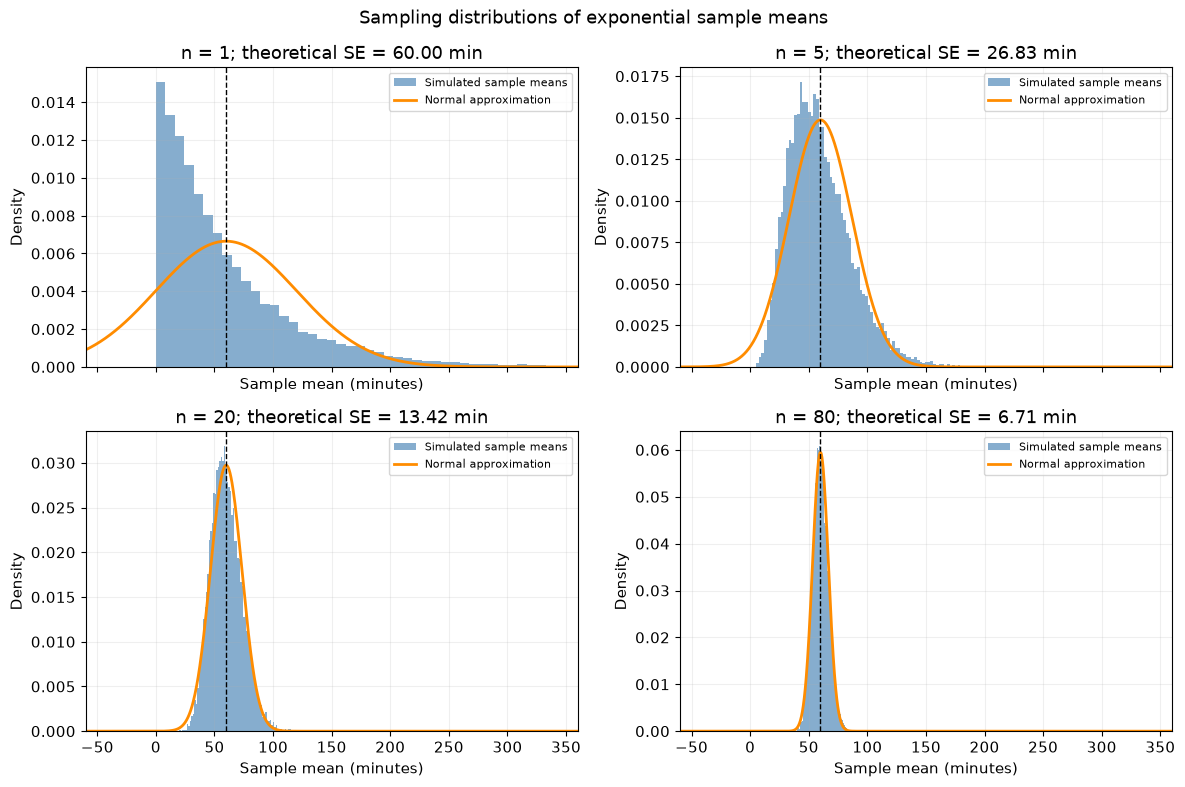

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
grid = np.linspace(-60, 360, 1500)
for ax, n in zip(axes.flat, sample_means):
    se = sigma / np.sqrt(n)
    ax.hist(sample_means[n], bins=90, density=True, alpha=0.65,
            color='steelblue', label='Simulated sample means')
    ax.plot(grid, stats.norm.pdf(grid, loc=mu, scale=se),
            color='darkorange', lw=2, label='Normal approximation')
    ax.axvline(mu, color='black', ls='--', lw=1)
    ax.set(title=f'n = {n}; theoretical SE = {se:.2f} min',
           xlabel='Sample mean (minutes)', ylabel='Density', xlim=(-60, 360))
    ax.legend(fontsize=8)
fig.suptitle('Sampling distributions of exponential sample means')
fig.tight_layout()
plt.show()

**Centre:** the sampling distributions remain centred at 60. Increasing $n$ does not change the population mean or systematically shift the estimator.

**Spread:** the standard error decreases as $1/\sqrt n$. To halve it, multiply the sample size by four. The empirical SD of the means should be close to the theoretical SE, with small Monte Carlo differences.

**Shape:** at $n=1$, the sample mean is just one exponential observation and is strongly right-skewed. Averaging more observations reduces skewness and produces a more bell-shaped distribution. The CLT says

$$\frac{\bar X-\mu}{\sigma/\sqrt n}\ \xrightarrow{d}\ N(0,1).$$

Thus, for sufficiently large $n$, $\bar X\approx N(\mu,\sigma^2/n)$. There is no universal sample size at which the approximation becomes perfect, especially for tail probabilities. With a normal population and independent observations, the mean would be exactly normal at every $n$. Here the population is exponential, so the normal overlay is an approximation at every finite $n$; for small $n$ it even assigns probability to impossible negative means.

**The CLT concerns sample means. It neither makes individual restoration times normal nor repairs dependence, drift, or unrepresentative sampling.**

### 1.3 Probability that the mean exceeds 75 minutes

Standardise 75 using the standard error of the mean, not the SD of an individual observation:

$$P(\bar X>75)\approx 1-\Phi\left(\frac{75-60}{60/\sqrt n}\right).$$

For simulation, count the means exceeding 75 and divide by 20,000. The Monte Carlo SE $\sqrt{\hat q(1-\hat q)/R}$ describes numerical uncertainty in this simulated probability, not the SE of restoration-time means.

In [4]:
probability_rows = []
for n in [20, 80]:
    simulated = np.mean(sample_means[n] > 75)
    z = (75 - mu) / (sigma / np.sqrt(n))
    approximate = stats.norm.sf(z)
    probability_rows.append({'n': n, 'z': z,
                             'simulation P(mean > 75)': simulated,
                             'CLT approximation': approximate,
                             'simulation minus CLT': simulated - approximate,
                             'Monte Carlo SE': np.sqrt(simulated * (1-simulated) / repetitions)})
probability_table = pd.DataFrame(probability_rows)
display(probability_table)

for row in probability_rows:
    n = row['n']
    simulated = row['simulation P(mean > 75)']
    approximate = row['CLT approximation']
    mc_se = row['Monte Carlo SE']
    display(Markdown(
        f'For **n = {n}**, simulation gives **{simulated:.5f}**, compared with '
        f'**{approximate:.5f}** from the CLT approximation. '
        f'The difference is **{simulated - approximate:.5f}** '
        f'and the Monte Carlo SE is **{mc_se:.5f}**.'))

display(Markdown(
    'At n = 20, the difference is small relative to simulation uncertainty. '
    'At n = 80, it is much larger than simulation uncertainty: the normal '
    'approximation understates this right-tail probability even though the '
    'sampling distribution looks more bell-shaped.'))


,n,z,simulation P(mean > 75),CLT approximation,simulation minus CLT,Monte Carlo SE
0,20,1.118034,0.13340,0.131776,0.001624,0.002404
1,80,2.236068,0.01865,0.012674,0.005976,0.000957


For **n = 20**, simulation gives **0.13340**, compared with **0.13178** from the CLT approximation. The difference is **0.00162** and the Monte Carlo SE is **0.00240**.

For **n = 80**, simulation gives **0.01865**, compared with **0.01267** from the CLT approximation. The difference is **0.00598** and the Monte Carlo SE is **0.00096**.

At n = 20, the difference is small relative to simulation uncertainty. At n = 80, it is much larger than simulation uncertainty: the normal approximation understates this right-tail probability even though the sampling distribution looks more bell-shaped.

The event becomes less likely as $n$ increases because 75 remains 15 minutes above the centre while the distribution becomes narrower. Differences between simulation and CLT reflect both finite-simulation error and the normal approximation's remaining error. A more normal-looking histogram does not guarantee a smaller *relative* error in every tail probability.

### 1.4 Smallest sample size giving SE at most 6 minutes

$$\frac{60}{\sqrt n}\le6
\iff \sqrt n\ge10
\iff n\ge100.$$

The smallest integer is therefore **100**. Check $n=99$ to establish minimality and simulate at $n=100$. The empirical SD is expected to be near 6, but can lie slightly above or below 6 due to simulation error; the requirement concerns the theoretical SE.

In [5]:
n_min = math.ceil((sigma / 6)**2)
means_100 = rng_clt.exponential(scale=mu, size=(repetitions, n_min)).mean(axis=1)
display(pd.DataFrame([{
    'minimum n': n_min, 'SE at n-1': sigma / np.sqrt(n_min-1),
    'SE at n': sigma / np.sqrt(n_min),
    'empirical SD at n': means_100.std(ddof=1)}]))

,minimum n,SE at n-1,SE at n,empirical SD at n
0,100,6.030227,6.0,6.063487


### 1.5 Running mean and the law of large numbers

Generate **one** sequence of 5,000 observations. At position $k$, plot the mean of its first $k$ observations:

$$\bar X_k=\frac{X_1+\cdots+X_k}{k}.$$

The law of large numbers (LLN) says that this average converges to the population mean as the number of iid observations grows. It does not promise that each new running average moves closer to 60, or that the average equals 60 after 5,000 observations.

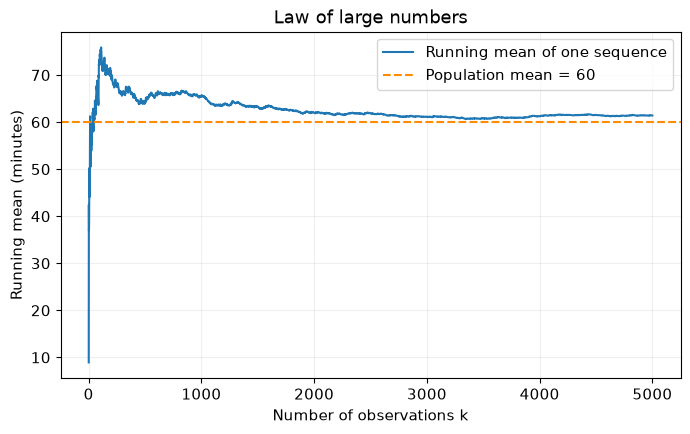

Final running mean: 61.4140 minutes


In [6]:
rng_lln = np.random.default_rng(2026)
sequence = rng_lln.exponential(scale=mu, size=5000)
k = np.arange(1, len(sequence)+1)
running_mean = np.cumsum(sequence) / k
fig, ax = plt.subplots()
ax.plot(k, running_mean, label='Running mean of one sequence')
ax.axhline(mu, color='darkorange', ls='--', label='Population mean = 60')
ax.set(xlabel='Number of observations k', ylabel='Running mean (minutes)',
       title='Law of large numbers')
ax.legend()
plt.show()
print(f'Final running mean: {running_mean[-1]:.4f} minutes')

This plot is a path of averages from **one growing sample**; its successive means overlap and are dependent. A sampling distribution describes means from **many repeated samples of a fixed size**. LLN concerns convergence of the average to $\mu$; CLT concerns the approximate distribution of its standardised fluctuations.

## Part 2: Mean sensor error

### 2.1 Parameter, estimates, SD, and SE

The parameter $\mu$ is the population mean calibration error for the sensor population represented by the independent selection. Positive error means that a sensor reads above the reference temperature. The assignment does not specify the full sampling frame, so generalisation must remain tied to the population and conditions represented by the study.

Compute:

$$\bar x=\frac1n\sum_i x_i,\quad s=\sqrt{\frac{\sum_i(x_i-\bar x)^2}{n-1}},\quad \widehat{\operatorname{SE}}(\bar X)=\frac{s}{\sqrt n}.$$

Use `ddof=1` for the sample variance denominator $n-1$. **SD** describes how individual sensor errors vary; **SE** estimates how sample means vary across repeated samples of $n$ sensors. Both have units of °C. Increasing sample size reduces SE but does not necessarily reduce the variability of individual sensors.

In [7]:
n_sensor = len(errors)
xbar = errors.mean()
s = errors.std(ddof=1)
se_sensor = s / np.sqrt(n_sensor)
display(pd.DataFrame([{'n': n_sensor, 'mean error (°C)': xbar,
                      'sample SD (°C)': s, 'estimated SE (°C)': se_sensor}]))

,n,mean error (°C),sample SD (°C),estimated SE (°C)
0,64,0.188266,0.625747,0.078218


### 2.2 Assessing the distribution

A histogram shows the observed sample's shape. A normal QQ-plot compares ordered observed errors with theoretical normal quantiles. An approximately straight QQ pattern supports approximate normality; systematic curvature or extreme points suggests departures.

A one-sample $t$ interval is exact under iid normal sampling and usually a reasonable approximation for a sample of 64 independent observations without severe skewness or influential outliers. Sample size alone does not guarantee validity. Independence comes from the design, not from the histogram or QQ-plot: sensors may share batches, environments, or measurement procedures even when their marginal distribution looks normal.

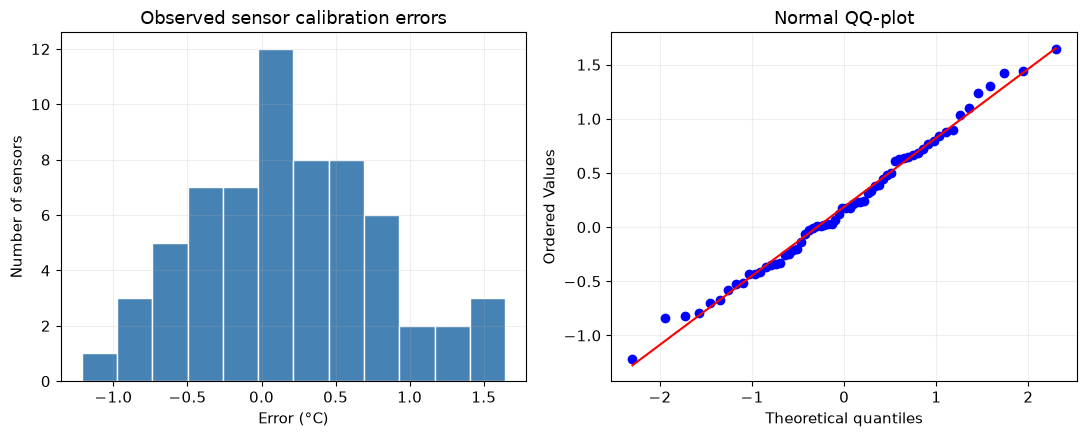

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(errors, bins=12, edgecolor='white', color='steelblue')
axes[0].set(title='Observed sensor calibration errors',
            xlabel='Error (°C)', ylabel='Number of sensors')
stats.probplot(errors, dist='norm', plot=axes[1])
axes[1].set_title('Normal QQ-plot')
fig.tight_layout()
plt.show()

**Assessment of these data:** the histogram is broadly unimodal with a modest right tail. The QQ points mostly follow the line, with some tail deviations and no visibly isolated extreme observation. With 64 independently selected sensors, a one-sample t interval appears reasonable as an approximation. These visual observations support the distributional approximation but do not prove normality or independence.

### 2.3 Constructing the 95% t interval

The population SD $\sigma$ is unknown, so replace it with $s$ and use a $t$ critical value:

$$\bar x\pm t_{1-\alpha/2,n-1}\frac{s}{\sqrt n}.$$

Step 1: $\alpha=0.05$ and $df=n-1=63$. Step 2: find the 0.975 quantile of $t_{63}$. Step 3: calculate $s/\sqrt n$. Step 4: multiply the critical value by the SE to obtain the margin of error. Step 5: subtract and add that margin to $\bar x$.

There are $n-1$ degrees of freedom because the deviations from the estimated mean sum to zero: knowing $n-1$ deviations determines the last. The $t$ distribution accounts for estimating $\sigma$, has heavier tails than normal, and approaches normal as degrees of freedom increase.

In [9]:
df = n_sensor - 1
tcrit = stats.t.ppf(0.975, df=df)
moe_sensor = tcrit * se_sensor
t95 = (xbar - moe_sensor, xbar + moe_sensor)
display(pd.DataFrame([{'df': df, 'critical t': tcrit, 'SE': se_sensor,
                      'margin of error': moe_sensor,
                      'lower': t95[0], 'upper': t95[1]}]))
scipy_t95 = stats.t.interval(confidence=0.95, df=df, loc=xbar, scale=se_sensor)
print('SciPy verification:', scipy_t95)
assert np.allclose(t95, scipy_t95)
display(Markdown(f'We estimate the population mean sensor error as **{xbar:.4f} °C**, '
                 f'with a 95% t interval of **[{t95[0]:.4f}, {t95[1]:.4f}] °C**. '
                 'This interval describes uncertainty about the population mean, '
                 'not the range containing 95% of individual sensor errors.'))

,df,critical t,SE,margin of error,lower,upper
0,63,1.998341,0.078218,0.156307,0.031959,0.344573


SciPy verification: (np.float64(0.03195868748729341), np.float64(0.34457256251270657))


We estimate the population mean sensor error as **0.1883 °C**, with a 95% t interval of **[0.0320, 0.3446] °C**. This interval describes uncertainty about the population mean, not the range containing 95% of individual sensor errors.

**Confidence-level interpretation:** if we repeatedly selected independent samples of 64 sensors under the same design and constructed intervals with this procedure, approximately 95% of those intervals would contain the fixed population mean (exactly 95% under the iid normal model). The endpoints vary across samples; the parameter does not. After calculation, this particular interval either contains the parameter or does not; frequentist 95% confidence is not a 95% probability assigned to the fixed parameter in this realised interval.

### 2.4 Confidence and precision

For the same data, higher confidence requires a larger critical value, so the margin of error and interval width increase. Width is $2\times$ margin of error. A narrower interval is more precise, but reducing confidence to obtain it gives lower repeated-sampling coverage.

In [10]:
sensor_rows = []
for confidence in [0.90, 0.95, 0.99]:
    critical = stats.t.ppf((1 + confidence)/2, df)
    margin = critical * se_sensor
    sensor_rows.append({'confidence': confidence, 'critical t': critical,
                        'lower': xbar-margin, 'upper': xbar+margin,
                        'width': 2*margin})
sensor_intervals = pd.DataFrame(sensor_rows)
display(sensor_intervals)

,confidence,critical t,lower,upper,width
0,0.90,1.669402,0.057688,0.318844,0.261156
1,0.95,1.998341,0.031959,0.344573,0.312614
2,0.99,2.656145,-0.019494,0.396025,0.415519


### 2.5 Planning for margin of error at most 0.10 °C

Use the observed $s$ as a planning approximation to $\sigma$, and the requested **normal** critical value:

$$E\approx z_{0.975}\frac{s}{\sqrt n},\qquad
n\ge\left(\frac{z_{0.975}s}{E}\right)^2,\quad E=0.10.$$

Round **up**, since rounding down could exceed the target margin. This is an approximate total sample size, not a guaranteed future width: the future sample SD may differ and a final $t$ interval uses a slightly larger critical value. If extending a comparable study, subtract 64 from the required total to obtain the approximate additional count.

In [11]:
z95 = stats.norm.ppf(0.975)
target_sensor = 0.10
raw_n_sensor = (z95 * s / target_sensor)**2
planned_n_sensor = math.ceil(raw_n_sensor)
display(pd.DataFrame([{'z': z95, 'planning s': s, 'target margin': target_sensor,
                      'unrounded n': raw_n_sensor, 'rounded total n': planned_n_sensor,
                      'approximate margin at n': z95*s/np.sqrt(planned_n_sensor),
                      'approximate margin at n-1': z95*s/np.sqrt(planned_n_sensor-1),
                      'additional sensors if extending': max(0, planned_n_sensor-n_sensor)}]))

display(Markdown(
    f'The smallest approximate total sample size is **{planned_n_sensor} sensors**. '
    f'Using the planning SD, its normal-based margin is '
    f'**{z95*s/np.sqrt(planned_n_sensor):.5f} °C**; '
    f'with one fewer sensor it is **{z95*s/np.sqrt(planned_n_sensor-1):.5f} °C**.'))


,z,planning s,target margin,unrounded n,rounded total n,approximate margin at n,approximate margin at n-1,additional sensors if extending
0,1.959964,0.625747,0.1,150.415872,151,0.099806,0.100139,87


The smallest approximate total sample size is **151 sensors**. Using the planning SD, its normal-based margin is **0.09981 °C**; with one fewer sensor it is **0.10014 °C**.

### 2.6 Percentile bootstrap interval

Treat the observed sample as an empirical population. Draw 10,000 samples **with replacement**, each containing 64 errors, and calculate each resampled mean. Replacement allows observations to appear several times or not at all. The percentile interval uses the 2.5th and 97.5th percentiles of the bootstrap means.

The bootstrap approximates uncertainty from repeated sampling using the observed distribution. It does not generate 10,000 new independent sensor measurements and does not increase the actual sample size.

,method,lower,upper,width
0,95% t,0.031959,0.344573,0.312614
1,95% percentile bootstrap,0.040759,0.341266,0.300508


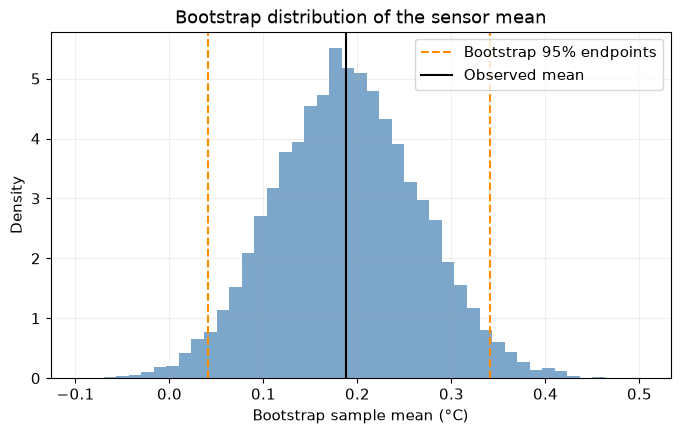

In [12]:
rng_bootstrap = np.random.default_rng(2026)
B = 10_000
bootstrap_means = rng_bootstrap.choice(errors, size=(B, n_sensor), replace=True).mean(axis=1)
boot95 = np.quantile(bootstrap_means, [0.025, 0.975])
display(pd.DataFrame([
    {'method': '95% t', 'lower': t95[0], 'upper': t95[1], 'width': t95[1]-t95[0]},
    {'method': '95% percentile bootstrap', 'lower': boot95[0], 'upper': boot95[1],
     'width': boot95[1]-boot95[0]}]))
fig, ax = plt.subplots()
ax.hist(bootstrap_means, bins=45, density=True, color='steelblue', alpha=0.7)
for i, value in enumerate(boot95):
    ax.axvline(value, color='darkorange', ls='--',
               label='Bootstrap 95% endpoints' if i == 0 else None)
ax.axvline(xbar, color='black', label='Observed mean')
ax.set(title='Bootstrap distribution of the sensor mean',
       xlabel='Bootstrap sample mean (°C)', ylabel='Density')
ax.legend()
plt.show()

Both methods estimate uncertainty about the same mean using the same observed sensors. Similar endpoints support the practical consistency of these calculations on this sample. Differences can result from the empirical distribution's shape, the finite number of bootstrap resamples, and the different interval constructions.

Here the bootstrap interval is approximately [0.0408, 0.3413] °C, compared with [0.0320, 0.3446] °C for the t interval. Their widths are approximately 0.3005 and 0.3126 °C respectively. Thus the bootstrap interval is slightly narrower, and both indicate a positive mean error while expressing appreciable uncertainty about its magnitude.

Agreement **cannot validate independence, representative selection, absence of systematic measurement bias, population normality, or actual 95% coverage**. Both methods inherit weaknesses of the same data. The ordinary resampling scheme assumes iid observations; percentile intervals have approximate, not guaranteed, nominal coverage.

## Part 3: False-rejection proportion

### 3.1 Parameter and point estimate

Let $Y_i=1$ if legitimate login attempt $i$ is falsely rejected, and 0 otherwise. For independent trials with a common rejection probability $p$, $Y_i$ is Bernoulli and the count $X=\sum_iY_i$ is binomial. The parameter $p$ is the probability of false rejection for legitimate attempts under the staged test conditions and the population of attempts those conditions represent.

$$\hat p=\frac{x}{n}=\frac{\sum_i y_i}{n}=\bar y.$$

Thus the sample proportion is the sample mean of a binary variable. The estimator $\hat P$ is random before sampling; its observed value $\hat p$ is an estimate. Under the model, it is unbiased: $E[\hat P]=p$.

In [13]:
n_access = len(rejects)
x = int(rejects.sum())
phat = x / n_access
display(pd.DataFrame([{'n': n_access, 'false rejections x': x,
                      'p-hat': phat, 'percentage': 100*phat,
                      'binary sample mean': rejects.mean()}]))

,n,false rejections x,p-hat,percentage,binary sample mean
0,240,20,0.083333,8.333333,0.083333


### 3.2 Primary 95% Wilson interval

For completeness, the Wilson components with $z=z_{0.975}$ are

$$D=1+\frac{z^2}{n},\quad
C=\frac{\hat p+z^2/(2n)}{D},\quad
H=\frac{z}{D}\sqrt{\frac{\hat p(1-\hat p)}{n}+\frac{z^2}{4n^2}}.$$

The endpoints are $C-H$ and $C+H$. The interval is centred on $C$, not generally on $\hat p$. Calculate these components and then verify with the required statsmodels Wilson function. We use only its interval formula, without performing a hypothesis test.

In [14]:
denominator = 1 + z95**2 / n_access
wilson_center = (phat + z95**2/(2*n_access)) / denominator
wilson_halfwidth = z95 / denominator * np.sqrt(
    phat*(1-phat)/n_access + z95**2/(4*n_access**2))
wilson_manual = (wilson_center-wilson_halfwidth, wilson_center+wilson_halfwidth)
display(pd.DataFrame([{'z': z95, 'denominator': denominator,
                      'adjusted centre': wilson_center, 'half-width': wilson_halfwidth,
                      'lower': wilson_manual[0], 'upper': wilson_manual[1]}]))
wilson95 = proportion_confint(count=x, nobs=n_access, alpha=0.05, method='wilson')
print('statsmodels Wilson verification:', wilson95)
assert np.allclose(wilson_manual, wilson95)
display(Markdown(f'The estimated false-rejection probability is **{phat:.4f} '
                 f'({100*phat:.2f}%)**, with a 95% Wilson interval of '
                 f'**[{wilson95[0]:.4f}, {wilson95[1]:.4f}]**, or '
                 f'**[{100*wilson95[0]:.2f}%, {100*wilson95[1]:.2f}%]**.'))

,z,denominator,adjusted centre,half-width,lower,upper
0,1.959964,1.016006,0.089897,0.035306,0.054591,0.125203


statsmodels Wilson verification: (0.054591485759776105, 0.12520344752485627)


The estimated false-rejection probability is **0.0833 (8.33%)**, with a 95% Wilson interval of **[0.0546, 0.1252]**, or **[5.46%, 12.52%]**.

The interval expresses uncertainty about the common false-rejection probability under the test conditions. Across repeated independent sets of 240 comparable staged attempts, Wilson intervals have coverage approximately at the stated confidence level. Because the binomial count is discrete, actual coverage need not be exactly 95%. This interval is neither a guarantee about future counts nor evidence that real-world conditions match the test conditions.

### 3.3 Wald interval and comparison

The Wald formula substitutes $\hat p$ into the approximate SE of a proportion:

$$\widehat{\operatorname{SE}}(\hat P)=\sqrt{\frac{\hat p(1-\hat p)}{n}},\qquad
\hat p\pm z_{0.975}\sqrt{\frac{\hat p(1-\hat p)}{n}}.$$

It is symmetric about $\hat p$. Wilson generally has better coverage, especially for small samples or probabilities near 0 or 1, and stays within $[0,1]$. Wald can extend outside this range or collapse to zero width when $x=0$ or $x=n$. A large sample can make these intervals similar, but does not remove Wald's general weaknesses. Here Wilson is the primary result.

In [15]:
se_p = np.sqrt(phat*(1-phat)/n_access)
wald_margin = z95 * se_p
wald95 = (phat-wald_margin, phat+wald_margin)
display(pd.DataFrame([{'p-hat': phat, 'estimated SE': se_p,
                      'z': z95, 'Wald margin': wald_margin}]))
display(pd.DataFrame([
    {'method': 'Wilson', 'lower': wilson95[0], 'upper': wilson95[1],
     'width': wilson95[1]-wilson95[0]},
    {'method': 'Wald', 'lower': wald95[0], 'upper': wald95[1],
     'width': wald95[1]-wald95[0]}]))
print(f'Observed false rejections x = {x}; observed non-rejections n-x = {n_access-x}')

display(Markdown(
    f'For these data, the 95% Wald interval is '
    f'**[{100*wald95[0]:.2f}%, {100*wald95[1]:.2f}%]**, '
    f'compared with **[{100*wilson95[0]:.2f}%, {100*wilson95[1]:.2f}%]** '
    f'for Wilson. Wilson is shifted upward and is slightly wider '
    f'({100*(wilson95[1]-wilson95[0]):.2f} versus '
    f'{100*(wald95[1]-wald95[0]):.2f} percentage points). '
    'Both intervals stay within [0, 1] here, but Wilson remains the preferred '
    'reported interval because of its better coverage properties.'))


,p-hat,estimated SE,z,Wald margin
0,0.083333,0.017841,1.959964,0.034967


,method,lower,upper,width
0,Wilson,0.054591,0.125203,0.070612
1,Wald,0.048366,0.118300,0.069934


Observed false rejections x = 20; observed non-rejections n-x = 220


For these data, the 95% Wald interval is **[4.84%, 11.83%]**, compared with **[5.46%, 12.52%]** for Wilson. Wilson is shifted upward and is slightly wider (7.06 versus 6.99 percentage points). Both intervals stay within [0, 1] here, but Wilson remains the preferred reported interval because of its better coverage properties.

### 3.4 Wilson intervals at different confidence levels

Higher confidence produces wider intervals for the same $n$ and count. Endpoints below are probabilities; multiply by 100 to express percentages. An absolute probability difference of 0.02 is **two percentage points**, not a relative change of 2%.

In [16]:
access_rows = []
for confidence in [0.90, 0.95, 0.99]:
    low, high = proportion_confint(x, n_access, alpha=1-confidence, method='wilson')
    access_rows.append({'confidence': confidence, 'lower': low, 'upper': high,
                        'width': high-low})
access_intervals = pd.DataFrame(access_rows)
display(access_intervals)

,confidence,lower,upper,width
0,0.90,0.058430,0.117527,0.059097
1,0.95,0.054591,0.125203,0.070612
2,0.99,0.047845,0.141240,0.093394


### 3.5 Planning for margin of error at most 0.02

Use the usual normal-approximation planning formula:

$$E\approx z_{0.975}\sqrt{\frac{p_0(1-p_0)}{n}},\qquad
n\ge\frac{z_{0.975}^2p_0(1-p_0)}{E^2},\quad E=0.02.$$

Here $p_0$ is a planning value. Since $p_0(1-p_0)$ is maximised at 0.5, choosing 0.5 gives the largest required sample size and is conservative when no prior estimate is available. Using the observed $\hat p$ generally requires fewer attempts, but depends on the pilot estimate being close to the future probability. These are approximate **total** sample sizes based on the normal planning formula, not an exact inversion of Wilson width or a guarantee for every future sample.

In [17]:
planning_rows = []
for label, p0 in [('Conservative p = 0.5', 0.5), ('Observed p-hat', phat)]:
    raw_n = z95**2 * p0*(1-p0) / 0.02**2
    total_n = math.ceil(raw_n)
    planning_rows.append({'planning method': label, 'planning p': p0,
                          'unrounded n': raw_n, 'rounded total n': total_n,
                          'approximate margin at n': z95*np.sqrt(p0*(1-p0)/total_n),
                          'approximate margin at n-1': z95*np.sqrt(p0*(1-p0)/(total_n-1))})
access_planning = pd.DataFrame(planning_rows)
display(access_planning)

display(Markdown(
    f'The conservative calculation requires **{int(access_planning.iloc[0]["rounded total n"]):,} '
    f'attempts**, compared with **{int(access_planning.iloc[1]["rounded total n"]):,} attempts** '
    f'using the observed proportion {phat:.4f}. '
    'The observed-proportion plan is smaller because its assumed Bernoulli '
    'variance is below the maximum variance at p = 0.5.'))


,planning method,planning p,unrounded n,rounded total n,approximate margin at n,approximate margin at n-1
0,Conservative p = 0.5,0.500000,2400.911763,2401,0.020000,0.020004
1,Observed p-hat,0.083333,733.611928,734,0.019995,0.020008


The conservative calculation requires **2,401 attempts**, compared with **734 attempts** using the observed proportion 0.0833. The observed-proportion plan is smaller because its assumed Bernoulli variance is below the maximum variance at p = 0.5.

## Part 4: AI-use and conclusion

### AI-use disclosure

**Tool and contribution:** OpenAI Codex (ChatGPT) produced most of the notebook's Python code and explanatory text, including simulations, plots, interval calculations, bootstrap resampling, sample-size planning, the conclusion, and exam preparation notes. It also reviewed and executed the completed notebook against the supplied CSV files.

**Changes made during completion:** The existing draft was retained and checked against the assignment. Codex corrected range and formula formatting, selected the project kernel, made the numerical tail comparisons follow the calculated results, and added explicit numerical interpretations of the Wald comparison and sample-size plans. The analysis stayed within the requested methods; no hypothesis tests were performed. Changes or rejections made independently by group members have not been recorded here.

**Verification:** Codex ran every code cell in order, checked the manual t interval against SciPy and the manual Wilson interval against statsmodels, inspected the generated plots, and checked that the conclusion contains 150–250 words. Data checks cover sample sizes, finite sensor errors, and binary login outcomes. These checks support the implementation, but cannot establish independence, representative sampling, or actual interval coverage.

**Group review:** The group should review and understand the work before submission and add any further tools, changes, rejections, and verification actually performed by its members.

### Overall conclusion


In [19]:
conclusion = f'''Repeated sampling shows that sample means vary even when the population
is unchanged. For independent exponential restoration times with mean and standard
deviation 60 minutes, sample means remain centred at 60 while their standard error
decreases as 60 divided by the square root of sample size. Their distributions become
more nearly normal as samples grow, although individual restoration times remain
right-skewed. The running-mean plot illustrates a different result: one growing
sample's average stabilises near the population mean.

The estimated population mean sensor calibration error is {xbar:.4f} °C,
with a 95% t confidence interval from {t95[0]:.4f} to {t95[1]:.4f} °C.
The estimated false-rejection probability is {phat:.4f} ({100*phat:.2f}%),
with a 95% Wilson interval from {wilson95[0]:.4f} to {wilson95[1]:.4f}.
These intervals quantify uncertainty about population parameters, rather than
the spread of individual observations. Their confidence levels describe the
coverage of interval procedures over repeated comparable samples.

Larger independent samples generally give narrower intervals, while higher
confidence requires wider intervals for fixed data. Sensor-study generalisation
is limited by the unspecified sampling frame and calibration conditions.
For access control, staged legitimate attempts may not represent everyday
users, devices, or environments. Increasing sample size reduces random
sampling uncertainty but does not remove these design limitations.'''
display(Markdown(conclusion))
print('Conclusion word count:', len(conclusion.split()))

Repeated sampling shows that sample means vary even when the population
is unchanged. For independent exponential restoration times with mean and standard
deviation 60 minutes, sample means remain centred at 60 while their standard error
decreases as 60 divided by the square root of sample size. Their distributions become
more nearly normal as samples grow, although individual restoration times remain
right-skewed. The running-mean plot illustrates a different result: one growing
sample's average stabilises near the population mean.

The estimated population mean sensor calibration error is 0.1883 °C,
with a 95% t confidence interval from 0.0320 to 0.3446 °C.
The estimated false-rejection probability is 0.0833 (8.33%),
with a 95% Wilson interval from 0.0546 to 0.1252.
These intervals quantify uncertainty about population parameters, rather than
the spread of individual observations. Their confidence levels describe the
coverage of interval procedures over repeated comparable samples.

Larger independent samples generally give narrower intervals, while higher
confidence requires wider intervals for fixed data. Sensor-study generalisation
is limited by the unspecified sampling frame and calibration conditions.
For access control, staged legitimate attempts may not represent everyday
users, devices, or environments. Increasing sample size reduces random
sampling uncertainty but does not remove these design limitations.

Conclusion word count: 197
